In [1]:
import pandas as pd

df = pd.read_csv('claims_data.csv')

## 1. Understanding our data

In [2]:
df.shape

(1243, 12)

In [3]:
df.dtypes

claim_id                     str
claim_type                   str
claim_amount             float64
customer_age               int64
customer_tenure_years    float64
claim_complexity             str
adjuster_experience      float64
digital_filing              bool
response_time_hours      float64
settlement_days          float64
satisfaction_score       float64
new_portal                  bool
dtype: object

In [4]:
df.isna().sum()

claim_id                 0
claim_type               0
claim_amount             0
customer_age             0
customer_tenure_years    0
claim_complexity         0
adjuster_experience      0
digital_filing           0
response_time_hours      0
settlement_days          0
satisfaction_score       0
new_portal               0
dtype: int64

In [5]:
import duckdb as db

con = db.connect()
con.execute("""
    CREATE OR REPLACE TABLE claims AS SELECT * FROM df
""")

con.execute("""
    SELECT
        SUM(claim_amount) as total_claim_amount,
        ROUND(AVG(claim_amount), 2) as mean_claim_amount,
        ROUND(STDDEV(claim_amount), 2) as stddev_claim_amount, 
        MIN(claim_amount) as min_claim_amount,
        MAX(claim_amount) as max_claim_amount
    FROM claims
""").df()



,total_claim_amount,mean_claim_amount,stddev_claim_amount,min_claim_amount,max_claim_amount
0,9508996.5,7650.04,12363.08,259.31,156945.33


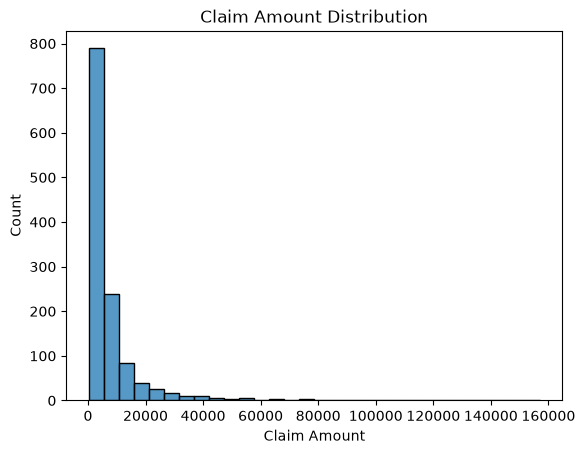

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x='claim_amount', bins=30)
plt.title('Claim Amount Distribution')
plt.xlabel('Claim Amount')
plt.show()

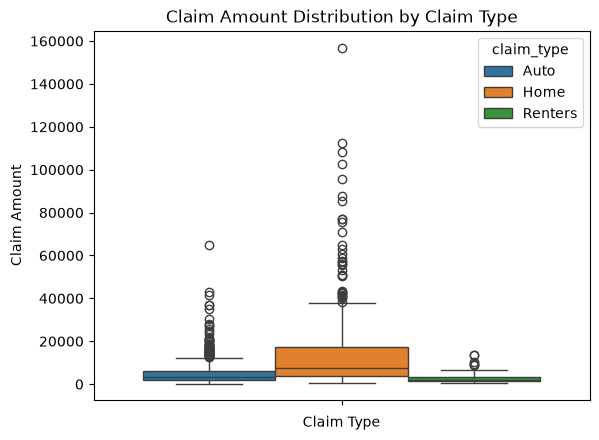

In [7]:
sns.boxplot(data=df, y='claim_amount', hue='claim_type')
plt.title('Claim Amount Distribution by Claim Type')
plt.xlabel('Claim Type')
plt.ylabel('Claim Amount')
plt.show()

In [8]:
df_claim_type = con.execute("""
    SELECT 
        claim_type, 
        COUNT(*) as count_claim_type,
    FROM claims
    GROUP BY claim_type
    ORDER BY claim_type
""").df()

df_claim_type

,claim_type,count_claim_type
0,Auto,758
1,Home,366
2,Renters,119


In [9]:
con.execute("""
    SELECT
        AVG(customer_age) as mean_customer_age,
        AVG(customer_tenure_years) mean_customer_tenure_years,
        AVG(response_time_hours) as mean_response_time,
        AVG(settlement_days) as mean_settlement_days,
        AVG(satisfaction_score) as mean_satisfaction_score
    FROM claims
""").df()

,mean_customer_age,mean_customer_tenure_years,mean_response_time,mean_settlement_days,mean_satisfaction_score
0,44.833467,6.174014,2.148681,12.000805,7.422607


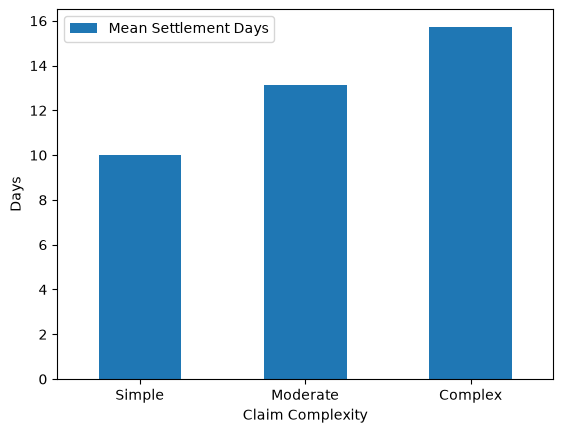

In [10]:
df_complexity = con.execute("""
    SELECT
        claim_complexity,
        AVG(settlement_days) as "Mean Settlement Days"
    FROM claims
    GROUP BY claim_complexity
""").df()

df_complexity = df_complexity.set_index('claim_complexity').loc[['Simple', 'Moderate', 'Complex']]

df_complexity.plot(kind='bar', xlabel='Claim Complexity', ylabel='Days', rot=0)
plt.show()

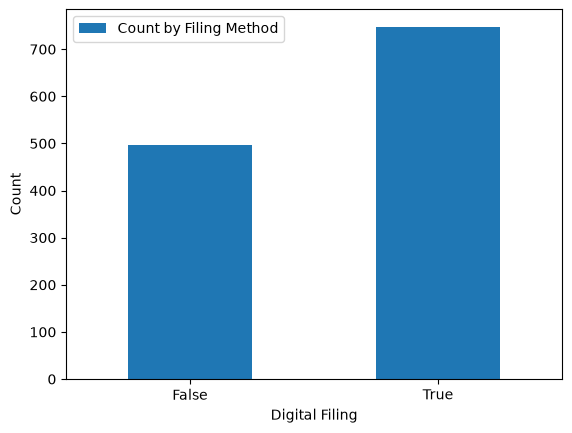

In [11]:
df_filing = con.execute("""
    SELECT
        digital_filing,
        COUNT(*) as "Count by Filing Method"
    FROM claims
    GROUP BY digital_filing
    ORDER BY digital_filing
""").df()

df_filing = df_filing.set_index('digital_filing')

df_filing.plot(kind='bar', xlabel='Digital Filing', ylabel='Count', rot=0)
plt.show()

### Exploratory initial analysis

**Dataset overview:**
- 1,243 claims
- 12 columns, properly typed
- 0 null values

**Claim Amount:**

| Statistic | Value |
|-----------|-------|
| Total | $9,508,996.50 |
| Mean | $7,650.04 |
| Standard Deviation | $12,363.08 |
| Min | $259.31 |
| Max | $156,945.33 |

**Distribution:** Right-skewed. This is expected for a claims dataset, with most claims at lower amounts and a few high-value claims creating a long tail.

**Distribution by claim type:**
- **Auto:** 758 claims. This is the claim type with the most claims, which could explain why it has the longest tail (outliers).
- **Home:** 366 claims. Outliers ranging from nearly $20k to above $60k.
- **Renters:** 119 claims. A few outliers, which makes sense given it's the smallest group.

**Average settlement days by claim complexity:**
- Simple: 10.02 days
- Moderate: 13.11 days
- Complex: 15.72 days

**Filing method count:**
- Phone filing: 496 claims
- Digital filing: 747 claims

**Additional statistics:**
- Mean customer age: 44.83 years
- Mean customer tenure: 6.17 years
- Mean response time: 2.14 hours
- Mean settlement days: 12.00 days
- Mean satisfaction score: 7.42 out of 10

---

## 2. Digital Filing Impact

**Question:** The company has been encouraging customers to file claims online instead of calling. Is there evidence this actually improves our operational metrics?

In [12]:
df_filing

,Count by Filing Method
digital_filing,
False,496
True,747


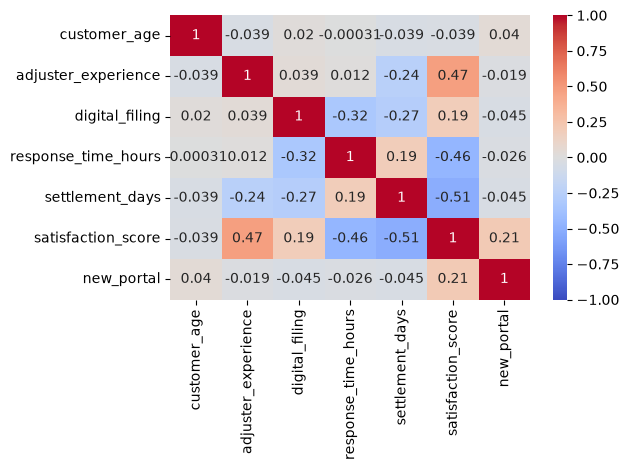

In [13]:
df_heatmap = df.drop(columns=['claim_id', 'claim_type', 'claim_complexity', 'claim_amount', 'customer_tenure_years'])
corr = df_heatmap.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

I created a heatmap to examine the correlation between digital_filing and other variables. The most significant correlations were with: response_time_hours, settlement_days, and satisfaction_score. These will be tested below.

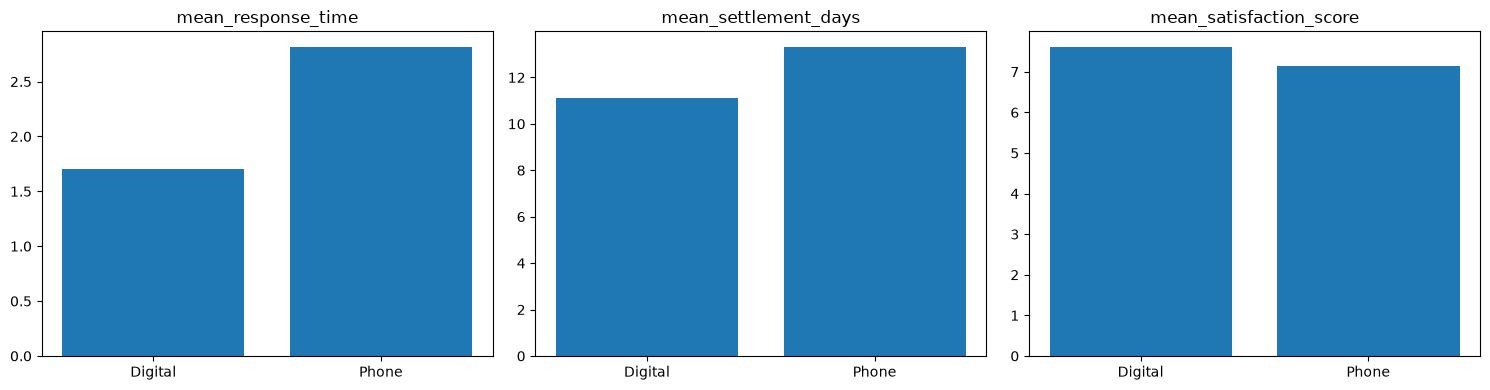

,digital_filing,mean_response_time,mean_settlement_days,mean_satisfaction_score
0,Digital,1.704846,11.125435,7.615529
1,Phone,2.817117,13.319153,7.132056


In [14]:
df_filing_stats = con.execute("""
    SELECT
        digital_filing,
        AVG(response_time_hours) as  mean_response_time,
        AVG(settlement_days) as mean_settlement_days, 
        AVG(satisfaction_score) as mean_satisfaction_score
    FROM claims
    GROUP BY digital_filing
""").df()

df_filing_stats['digital_filing'] = df_filing_stats['digital_filing'].map({False: 'Phone', True: 'Digital'})

cols = ['mean_response_time', 'mean_settlement_days', 'mean_satisfaction_score']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    ax.bar(df_filing_stats['digital_filing'], df_filing_stats[col])
    ax.set_title(col)

plt.tight_layout()
plt.show()

df_filing_stats

Simple barplots to see the average value for every group.

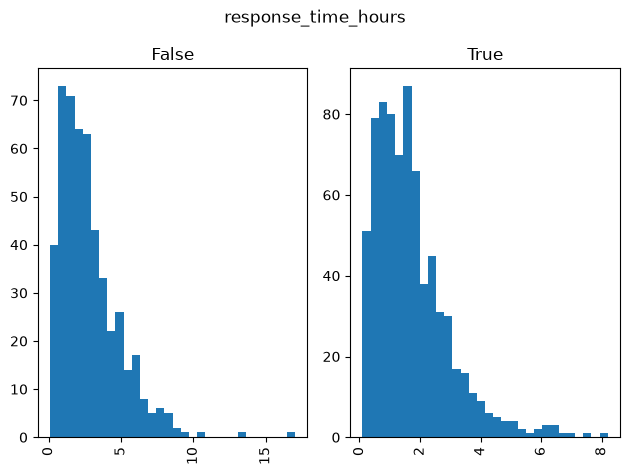

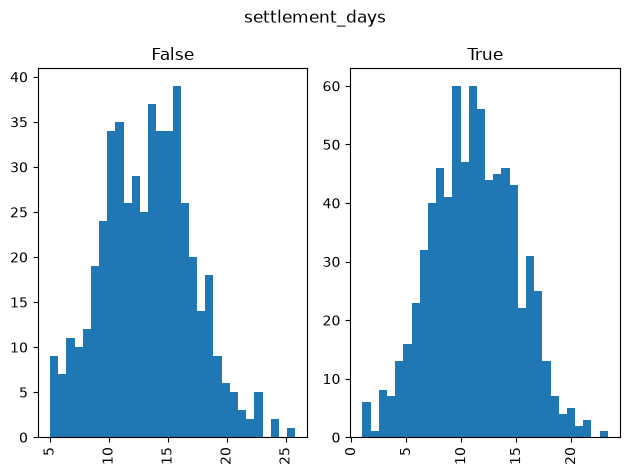

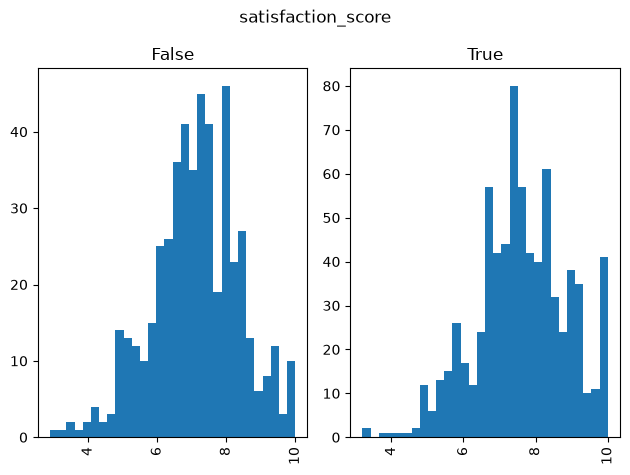

In [15]:
for col in ['response_time_hours', 'settlement_days', 'satisfaction_score']:
    df[col].hist(by=df['digital_filing'], bins=30)
    plt.suptitle(col)
    plt.tight_layout()
    plt.show()

Created hist plots to see the distribution of every group per filing method.

- satisfaction_score and settlement_days are approximately normally distributed. 
- response_time_hours is right-skewed. 

This will help me to choose the proper test later.

---
For this section, I'll use the pingouin library because it's convenient. It will give me the required values in one call.

In [16]:
import pingouin as pg

phone = df[~df['digital_filing']]
digital = df[df['digital_filing']]

pg.mwu(digital['response_time_hours'], phone['response_time_hours'])

,U_val,alternative,p_val,RBC,CLES
MWU,119117.0,two-sided,1.379654e-26,-0.357014,0.321493


In [17]:
pg.ttest(digital['settlement_days'], phone['settlement_days'])

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-9.912052,1069.822401,two-sided,3.232278e-22,"[-2.63, -1.76]",0.572614,1.0,1.396e+19


In [18]:
pg.ttest(digital['satisfaction_score'], phone['satisfaction_score'])

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,6.62518,1055.515866,two-sided,5.517204e-11,"[0.34, 0.63]",0.38425,0.999998,1.194e+08


In [19]:
import pingouin as pg

print(pg.compute_effsize(digital['satisfaction_score'], phone['satisfaction_score'], eftype='cohen'))
print(pg.compute_effsize(digital['settlement_days'], phone['settlement_days'], eftype='cohen'))

0.38424992764760096
-0.5726141674964867


In [20]:
med_digital = digital['response_time_hours'].median()
med_phone = phone['response_time_hours'].median()

difference = med_phone - med_digital
print(difference)
print(difference / med_phone)

0.865
0.3673036093418259


### Findings

**1. Digital vs. Phone: Satisfaction Score**

- **H₀:** Digital and phone filing have the same true average satisfaction score.
- **H₁:** Digital and phone filing have different true average satisfaction scores.
- **Test used:** Welch's t-test (satisfaction is approximately normal and the samples are large).
- **Result:**
  - p-value < 0.0001, so we reject H₀
  - Cohen's d = 0.38 (small to medium effect)
  - 95% CI for the difference: [0.34, 0.63] points
- **Interpretation:** Digital filers report statistically significantly higher satisfaction than phone filers, by about 0.34 to 0.63 points on the 10-point scale. The difference is statistically significant but modest in practical size.

**2. Digital vs. Phone: Settlement Days**

- **H₀:** Digital and phone filing have the same true average settlement days.
- **H₁:** Digital and phone filing have different true average settlement days.
- **Test used:** Welch's t-test (settlement days are approximately normal and the samples are large).
- **Result:**
  - p-value < 0.0001, so we reject H₀
  - Cohen's d = 0.57 (medium effect)
  - 95% CI for the difference: [-2.63, -1.76] days
- **Interpretation:** Digital filed claims are settled 1.76 to 2.63 days faster. The difference is statistically significant.

**3. Digital vs. Phone: Response Time Hours**

- **H₀:** The response time distributions for digital and phone filing are the same (neither tends to be higher).
- **H₁:** The response time distributions for digital and phone filing differ (one tends to have higher values).
- **Test used:** Mann-Whitney U test (data is right-skewed).
- **Result:**
  - p-value < 0.0001, so we reject H₀
  - Median gap = 0.865 hours (digital is 37% lower)
  - Rank-biserial correlation = -0.36
- **Interpretation:** The median response time for digital filers is 0.865 hours (about 37%) lower than for phone filers. The difference is statistically significant.

**Considerations:** No confidence interval includes zero, which agrees with the p-values.

**Business insights:** Digital filing is associated with better results on all three metrics:
1. Digital filers show satisfaction 0.34 to 0.63 points higher
2. Digital filed claims are settled about 1.76 to 2.63 days faster
3. Digital filers get a median response time about 37% lower

---

## 3. New Portal Evaluation

**Question:** The company rolled out a new digital claims portal to half our customers as a test. Did it improve customer satisfaction? Should we expand it to everyone?

In [21]:
con.execute("""
    SELECT  
        new_portal,
        COUNT(*) as total,
        CASE 
            WHEN new_portal THEN 'Treatment Group'
            ELSE 'Control Group'
        END as group
    FROM claims
    GROUP BY new_portal
    ORDER BY new_portal
""").df()

,new_portal,total,group
0,False,638,Control Group
1,True,605,Treatment Group


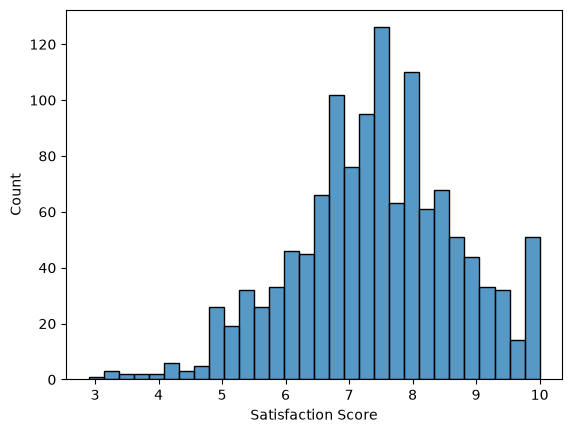

In [22]:
sns.histplot(data=df, x='satisfaction_score', bins=30)
plt.xlabel('Satisfaction Score')
plt.show()

In [23]:
from scipy.stats import ttest_ind, mannwhitneyu
import scipy.stats as stats

control_group = df[~df['new_portal']]['satisfaction_score']
treatment_group = df[df['new_portal']]['satisfaction_score']

t_stat, p_value = ttest_ind(treatment_group, control_group, alternative='greater')

print(f'Control average satisfaction score: {control_group.mean():.2f}')
print(f'Treatment average satisfaction score: {treatment_group.mean():.2f}')
print(f'T-statistic: {t_stat:.3f}')
print(f'p-value: {p_value:.4f}')

Control average satisfaction score: 7.17
Treatment average satisfaction score: 7.69
T-statistic: 7.401
p-value: 0.0000


In [24]:
import numpy as np

def calculate_stats(data):
    ci = stats.t.interval(
        confidence=0.95,
        df=data['n'] - 1,
        loc=data['mean'],
        scale=data['se']
    )

    return {**data, 'lower_ci': ci[0], 'upper_ci': ci[1]}

control_info = {
    'mean': np.mean(control_group),
    'std': np.std(control_group, ddof=1),
    'n': len(control_group),
    'se': np.std(control_group, ddof=1) / np.sqrt(len(control_group))
}

treatment_info = {
    'mean': np.mean(treatment_group),
    'std': np.std(treatment_group, ddof=1),
    'n': len(treatment_group),
    'se': np.std(treatment_group, ddof=1) / np.sqrt(len(treatment_group))
}

control_values = calculate_stats(control_info)
treatment_values = calculate_stats(treatment_info)

dof = control_info['n'] + treatment_info['n'] - 2
t_crit = stats.t.ppf(0.975, dof)

diff = treatment_values['mean'] - control_values['mean']
se_diff = np.sqrt(control_values['se']**2 + treatment_values['se']**2)
lower_ci = diff - (t_crit * se_diff)
upper_ci = diff + (t_crit * se_diff)

print(f"Control Group: Mean: {control_values['mean']:.2f} (95% CI: {control_values['lower_ci']:.2f} - {control_values['upper_ci']:.2f})")
print(f"Treatment Group: Mean: {treatment_values['mean']:.2f} (95% CI: {treatment_values['lower_ci']:.2f} - {treatment_values['upper_ci']:.2f})")
print(f'Mean difference: {diff:.2f} (95% CI: {lower_ci:.2f} - {upper_ci:.2f})')
print(f"Relative lift: {(treatment_values['mean'] / control_values['mean'] - 1) * 100:.2f}")

Control Group: Mean: 7.17 (95% CI: 7.07 - 7.27)
Treatment Group: Mean: 7.69 (95% CI: 7.60 - 7.79)
Mean difference: 0.53 (95% CI: 0.39 - 0.67)
Relative lift: 7.34


In [25]:
u_stat, p_value = mannwhitneyu(treatment_group, control_group, alternative='greater')
print(f'Control average satisfaction score: {control_group.mean():.2f}')
print(f'Treatment average satisfaction score: {treatment_group.mean():.2f}')
print(f'U-statistic: {u_stat:.3f}')
print(f'p-value: {p_value:.4f}')

Control average satisfaction score: 7.17
Treatment average satisfaction score: 7.69
U-statistic: 239152.000
p-value: 0.0000


### Analysis

**Hypothesis:** The new portal has an effect on customer satisfaction score.

**Test Design:**
- **Control:** 638 customers using the current claims portal
- **Treatment:** 605 customers using the new claims portal
- Customers were randomly assigned to treatment or control groups

**Results:**
- Control: Mean 7.17 (95% CI: 7.07 - 7.27)
- Treatment: Mean 7.69 (95% CI: 7.60 - 7.79)
- Absolute lift: 0.53 points (95% CI of the difference: 0.39 - 0.67)
- Relative lift: 7.34% compared to the control group
- Statistical significance: p < 0.0001

**Test choice:** I used a t-test as my primary test because the sample is large enough for it to work well, even with slightly left-skewed scores. I also ran a Mann-Whitney U test as a double check. Both p-values are below 0.0001, supporting the same finding.

**Interpretation:**

The effect is real: it's statistically significant, and every test agrees. The size is about +0.5 points on a 10-point scale, and even the low end of the confidence interval (+0.39) represents a positive improvement.

**Business Impact:**

The new portal increased satisfaction by 0.53 points (7.34% relative to the old portal). We are 95% confident the true increase is between 0.39 and 0.67 points.

**Recommendation:**

**Roll out the new portal to all customers.** Before the final rollout, confirm that implementation costs are justified by an expected improvement of 0.39 to 0.67 satisfaction points. This finding aligns with Question 2's results showing that digital filing improvements drive higher satisfaction.

---

## 4. Satisfaction Drivers

**Question:** What factors most influence customer satisfaction with our claims process? Which should we prioritize for improvement?

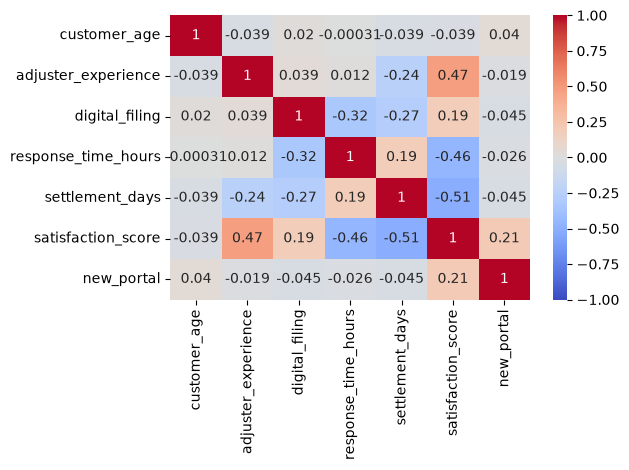

Looking at the heatmap I created in Q2, we can see the strongest correlations with satisfaction_score are: adjuster_experience, digital_filing, response_time_hours, settlement_days, and new_portal. These will be the variables I'll use in the regression analysis.

I built a multiple regression model to identify which factors most influence customer satisfaction, controlling for the effects of all other variables.

In [53]:
import statsmodels.formula.api as smf

model = smf.ols('satisfaction_score ~ adjuster_experience + digital_filing + response_time_hours + settlement_days + new_portal', data=df)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:     satisfaction_score   R-squared:                       0.577
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     337.8
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          2.94e-228
Time:                        21:11:13   Log-Likelihood:                -1534.9
No. Observations:                1243   AIC:                             3082.
Df Residuals:                    1237   BIC:                             3113.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  8

In [54]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X = df[['response_time_hours', 'settlement_days', 'new_portal', 'adjuster_experience', 'digital_filing']]
X = sm.add_constant(X)

vif = pd.DataFrame({
    'variable': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif)

              variable       VIF
0                const  1.000000
1  response_time_hours  1.132958
2      settlement_days  1.166096
3           new_portal  1.007787
4  adjuster_experience  1.067417
5       digital_filing  1.180295


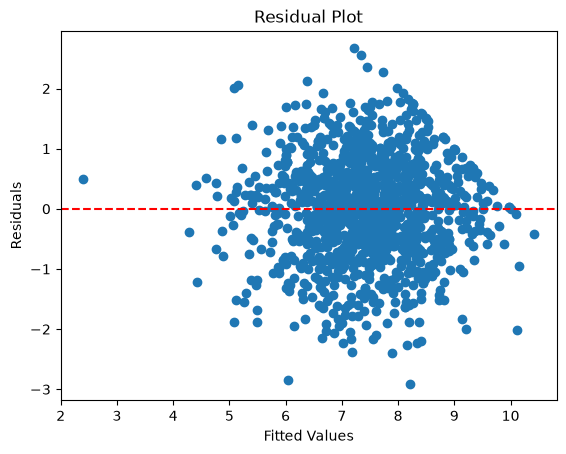

In [45]:
plt.scatter(results.fittedvalues, results.resid)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

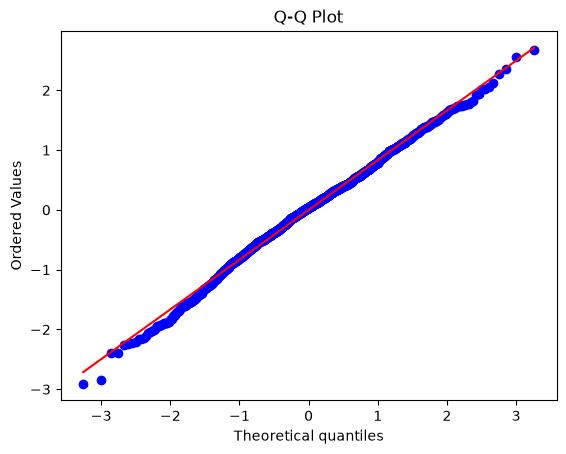

In [33]:
stats.probplot(results.resid, dist='norm', plot=plt)
plt.title('Q-Q Plot')
plt.show()

In [55]:
new_data = pd.DataFrame({
    'adjuster_experience': [10, 0.75, 2, 15, 5.4],
    'digital_filing': [True, True, False, False, True],
    'response_time_hours': [2, 0.20, 4.5, 3.85, 2.80],
    'settlement_days': [10, 16, 14, 12, 9.30],
    'new_portal': [True, True, False, False, True]
})

predictions = results.predict(new_data)
print(predictions)

0    8.454990
1    7.000370
2    5.731412
3    8.036824
4    7.620653
dtype: float64


In [46]:
import statsmodels.formula.api as smf

model = smf.ols('satisfaction_score ~ adjuster_experience + digital_filing + new_portal', data=df)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:     satisfaction_score   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     174.7
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           1.93e-94
Time:                        20:42:40   Log-Likelihood:                -1850.7
No. Observations:                1243   AIC:                             3709.
Df Residuals:                    1239   BIC:                             3730.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  5

In [34]:
df.describe()

,claim_amount,customer_age,customer_tenure_years,adjuster_experience,response_time_hours,settlement_days,satisfaction_score
count,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000
mean,7650.037409,44.833467,6.174014,6.071842,2.148681,12.000805,7.422607
std,12363.083753,14.066970,3.547938,3.492084,1.698352,3.977457,1.279824
min,259.310000,22.000000,0.500000,0.500000,0.100000,1.000000,2.900000
25%,1909.480000,35.000000,3.700000,3.400000,0.950000,9.300000,6.600000
50%,3875.770000,44.000000,5.400000,5.400000,1.710000,11.900000,7.400000
75%,7878.905000,54.000000,8.000000,8.000000,2.805000,14.800000,8.300000
max,156945.330000,85.000000,24.800000,20.000000,17.050000,25.800000,10.000000


### Results

**Predictors:**
- Adjuster experience
- Digital filing
- Response time hours
- Settlement days
- New portal

**Coefficient estimates:**

| Variable | Coefficient | 95% CI | Interpretation |
|----------|------------|---------|----------------|
| Digital filing | -0.12 | [-0.22, -0.02] | Digital filing reduces satisfaction by 0.12 points when controlling for response time and settlement days. This negative direct effect occurs because digital filing speeds up the process. |
| New portal | 0.47 | [0.38, 0.57] | The new portal increases satisfaction by 0.47 points. |
| Adjuster experience | 0.15 | [0.13, 0.16] | Each additional year of experience increases satisfaction by 0.15 points. |
| Response time hours | -0.31 | [-0.34, -0.28] | Each additional hour of response time reduces satisfaction by 0.31 points. |
| Settlement days | -0.11 | [-0.12, -0.10] | Each additional day to settlement reduces satisfaction by 0.11 points. |

**Model performance:**
- R² = 0.58: The five variables together explain 58% of the variation in satisfaction scores.
- Residual plot: No sign of curvature or unequal spread.
- Q-Q plot: Residuals are approximately normal, with mild tails.

**Priorities:** To prioritize interventions, I calculated the impact of a one-standard-deviation change in each variable:

| Variable | Effect on score (coef × SD) |
|----------|----------------------------|
| Response time hours | ~-0.52 |
| Adjuster experience | ~0.51 |
| Settlement days | ~-0.44 |
| New portal | ~0.24 |
| Digital filing (direct) | ~-0.06 |
| Digital filing (total, Model 2) | ~0.22 |

Speed (response time and settlement days) and adjuster experience have the largest impacts. Digital filing matters least directly but helps mainly by speeding up claims.

**Confidence intervals:** None of the CIs include zero, so all five effects are statistically significant. Digital filing's direct effect is small, and its interval is close to zero.

**Considerations:**
- For the second model, I removed response_time_hours and settlement_days because they likely act as **mediators** (digital filing speeds up the process, which raises satisfaction). This model shows digital filing's **total effect** (+0.46), not just its direct effect.
- These results show the effect of each variable on satisfaction score, holding the others constant. The data is observational, so they show associations, not proven causes.

---

### Predictions

Using the first model, I predicted satisfaction scores for five hypothetical claims within the range of the data:

| Claim | Adjuster exp (yrs) | Digital filing | New portal | Response time (h) | Settlement days | Predicted satisfaction |
|-------|-------------------|----------------|------------|-------------------|-----------------|----------------------|
| A | 10 | Yes | Yes | 2.00 | 10 | 8.45 |
| B | 0.75 | Yes | Yes | 0.20 | 16 | 7.00 |
| C | 2 | No | No | 4.50 | 14 | 5.73 |
| D | 15 | No | No | 3.85 | 12 | 8.04 |
| E | 5.4 | Yes | Yes | 2.80 | 9.30 | 7.62 |

Claim B has a very fast response but a long settlement (16 days), which pulls its score down despite the new portal and digital filing. Claim C, with the old portal, slow response, and limited adjuster experience, scores lowest.

---

### Business Insights

**Key drivers of satisfaction:**
1. **Response time** has the largest impact (~0.52 points per standard deviation)
2. **Adjuster experience** has nearly equal impact (~0.51 points per standard deviation)
3. **Settlement days** also drives significant variation (~0.44 points per standard deviation)
4. **New portal** and **digital filing** both contribute positively

**Recommendations:**

1. **Reduce response time first.** It has the largest effect on satisfaction. Focus on processes that get adjusters to claims faster.

2. **Reduce settlement days.** This is the second-highest operational priority and could increase satisfaction by ~0.44 points per standard deviation improvement.

3. **Roll out the new portal.** The A/B test shows a +0.53-point increase (95% CI: 0.39 to 0.67), consistent with the regression estimate (+0.47).

4. **Promote digital filing.** Its overall effect is positive (+0.46) because it speeds up claims, even though the direct effect is slightly negative when controlling for speed.

5. **Support adjuster experience.** Invest in training and retention, since experience has one of the largest effects on satisfaction.